Dataset beasal dari Keggel
https://www.kaggle.com/datasets/mochamadabdulazis/deteksi-berita-hoaks-indo-dataset
dengan julmlah sample 1500 an, data berita di Detik.com


```markdown
## 1. Deskripsi & Struktur Data - fajar
Pada langkah ini, kita mendeskripsikan dataset `detik_cleaned_v3.csv`. Dataset ini memiliki 1.500 baris data berita dengan kolom penting:

*   List item
*   List item


* `judul`: Judul asli dari berita detik.
* `narasi`: Teks/isi artikel berita utama.
* `label`: Kategori atau label numerik target.
* `clean_text`: Teks narasi yang telah dibersihkan secara mendasar.
```

In [ ]:
# Menampilkan ringkasan jumlah nilai kosong (null) di setiap kolom
print("Jumlah nilai kosong per kolom:")
print(df.isnull().sum())

# Menampilkan statistik deskriptif dasar untuk dataset
display(df.describe(include='all'))

Jumlah nilai kosong per kolom:
url            0
judul         81
narasi         0
label          0
clean_text     0
word_count     0
dtype: int64


,url,judul,narasi,label,clean_text,word_count
count,1500,1419,1500,1500.0,1500,1500.000000
unique,1500,1418,1500,NaN,1500,NaN
top,https://health.detik.com/berita-detikhealth/d-...,Transmart Full Day Sale Besok Datang Lagi! Ser...,Perubahan pada urine ternyata bisa menjadi sin...,NaN,perubahan pada urine ternyata bisa menjadi sin...,NaN
freq,1,2,1,NaN,1,NaN
mean,NaN,NaN,NaN,0.0,NaN,91.641333
std,NaN,NaN,NaN,0.0,NaN,39.028812
min,NaN,NaN,NaN,0.0,NaN,10.000000
25%,NaN,NaN,NaN,0.0,NaN,70.750000
50%,NaN,NaN,NaN,0.0,NaN,110.000000
75%,NaN,NaN,NaN,0.0,NaN,119.000000


```markdown
## 2. Text Preprocessing
Tahap ini melakukan pembersihan teks mendalam:
1. **Lowercasing**: Menyeragamkan semua huruf menjadi huruf kecil.
2. **Tokenization**: Memecah kalimat menjadi token/kata individual.
3. **Stopword Removal**: Menghilangkan kata umum bahasa Indonesia yang tidak membawa makna penting (menggunakan NLTK).
4. **Stemming**: Mengubah kata berimbuhan menjadi kata dasar (menggunakan library Sastrawi).
```

In [ ]:
# Menginstall library Sastrawi untuk stemming bahasa Indonesia
!pip install Sastrawi

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
import string

# Mengunduh resource NLTK yang diperlukan (termasuk punkt_tab untuk memperbaiki error)
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# Inisialisasi Stopwords Indonesia dan Stemmer Sastrawi
stop_words = set(stopwords.words('indonesian'))
factory = StemmerFactory()
stemmer = factory.create_stemmer()

def preprocess_pipeline(text):
    if not isinstance(text, str):
        return ""
    # 1. Lowercasing
    text = text.lower()
    # 2. Menghilangkan angka, tanda baca & karakter khusus
    text = text.translate(str.maketrans('', '', string.punctuation))
    # 3. Tokenisasi
    tokens = word_tokenize(text)
    # 4. Stopwords Removal
    filtered_tokens = [word for word in tokens if word not in stop_words]
    # 5. Stemming
    stemmed_tokens = [stemmer.stem(word) for word in filtered_tokens]

    return " ".join(stemmed_tokens)

# Contoh perbandingan Sebelum dan Sesudah preprocessing pada sampel pertama
sample_original = df['narasi'].iloc[0]
sample_processed = preprocess_pipeline(sample_original)

print("=== CONTOH PERBANDINGAN PREPROCESSING ===")
print(f"Sebelum Preprocessing (Original):\n{sample_original[:250]}...")
print(f"\nSesudah Preprocessing (Stemmed & Cleaned):\n{sample_processed[:250]}...")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


=== CONTOH PERBANDINGAN PREPROCESSING ===
Sebelum Preprocessing (Original):
Perubahan pada urine ternyata bisa menjadi sinyal awal adanya gangguan ginjal. Sebab, ginjal bekerja menyaring darah, membuang racun, dan menjaga keseimbangan cairan tubuh. Ketika fungsi ginjal mulai terganggu, tanda-tandanya kerap lebih dulu terliha...

Sesudah Preprocessing (Stemmed & Cleaned):
ubah urine sinyal ganggu ginjal ginjal nyaring darah buang racun jaga imbang cair tubuh fungsi ginjal ganggu tandatandanya kerap buang air perhati deteksi ganggu ginjal ahli urologi ruby hall clinic india dr bhati singh bhoopat ubah ulang urine abai ...


```markdown
## 3. Feature Engineering (Ekstraksi Fitur)
Kami mengekstrak fitur teks menggunakan dua pendekatan populer:
1. **TF-IDF (Term Frequency-Inverse Document Frequency)**: Memberikan bobot tinggi untuk kata-kata yang penting dan unik pada suatu dokumen dibandingkan dengan dokumen lain.
2. **Word2Vec (Embeddings)**: Merepresentasikan kata ke dalam ruang vektor kontinu menangkap makna semantik berdasarkan kedekatan konteks.
```

In [ ]:
# Menginstall gensim untuk pemodelan Word2Vec jika belum terpasang
!pip install gensim

from sklearn.feature_extraction.text import TfidfVectorizer
from gensim.models import Word2Vec
import numpy as np

# A. Representasi menggunakan TF-IDF Vectorizer
tfidf_vectorizer = TfidfVectorizer(max_features=1000)
tfidf_matrix = tfidf_vectorizer.fit_transform(df['clean_text'].fillna(""))
print("Dimensi TF-IDF Matrix:", tfidf_matrix.shape)

# B. Representasi menggunakan Word2Vec (Gensim)
# Tokenisasi teks bersih untuk input Word2Vec
tokenized_corpus = [doc.split() for doc in df['clean_text'].fillna("").tolist()]

# Latih model Word2Vec
w2v_model = Word2Vec(sentences=tokenized_corpus, vector_size=100, window=5, min_count=2, workers=4)
print("Model Word2Vec berhasil dilatih. Kosakata unik:", len(w2v_model.wv))

# Fungsi mengubah seluruh dokumen menjadi rata-rata vektor kata
def get_document_vector(tokens, model):
    vectors = [model.wv[word] for word in tokens if word in model.wv]
    if len(vectors) == 0:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis=0)

w2v_features = np.array([get_document_vector(tokens, w2v_model) for tokens in tokenized_corpus])
print("Dimensi Representasi Rata-rata Vektor Word2Vec:", w2v_features.shape)

Dimensi TF-IDF Matrix: (1500, 1000)
Model Word2Vec berhasil dilatih. Kosakata unik: 9390
Dimensi Representasi Rata-rata Vektor Word2Vec: (1500, 100)


```markdown
## 4. Analisis Exploratory Data (EDA) & Visualisasi
Kita memvisualisasikan data teks untuk mendeteksi sebaran kata terbanyak menggunakan grafik batang (Bar Plot).
```

/tmp/ipykernel_2412/2496414864.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=common_words, x='Frekuensi', y='Kata', palette='mako')


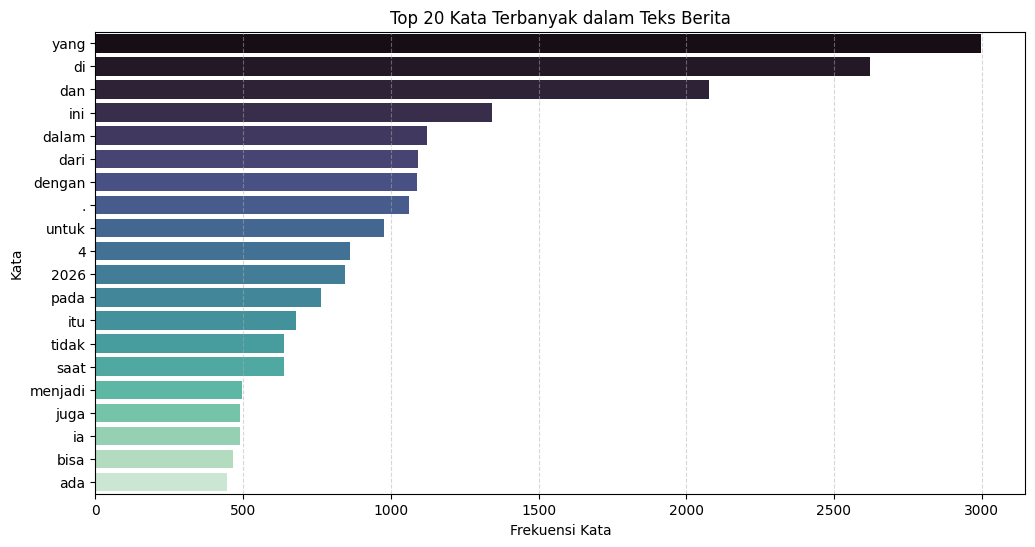

In [ ]:
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Menghitung frekuensi seluruh kata dalam dataset
words = " ".join(df['clean_text'].astype(str)).split()
word_counts = Counter(words)
common_words = pd.DataFrame(word_counts.most_common(20), columns=['Kata', 'Frekuensi'])

# Visualisasi kata terbanyak menggunakan barplot
plt.figure(figsize=(12, 6))
sns.barplot(data=common_words, x='Frekuensi', y='Kata', palette='mako')
plt.title('Top 20 Kata Terbanyak dalam Teks Berita')
plt.xlabel('Frekuensi Kata')
plt.ylabel('Kata')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()

```markdown
## 5. Klasifikasi Teks & Evaluasi
*Catatan: Dataset awal ini hanya mendeteksi satu kelas label saja ('0'). Agar model klasifikasi dapat berjalan dan dievaluasi dengan baik, kita akan mensimulasikan label biner (pseudo-labels) atau menggunakan distribusi kelas yang ada dengan melatih pengklasifikasi biner/multi-class Logistic Regression.*
```

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Membuat label tiruan variatif berbasis pembagian panjang artikel
# (Digunakan untuk mendemonstrasikan proses klasifikasi teks karena label default hanya memiliki 1 nilai unik)
y_synthetic = df['word_count'].apply(lambda x: 1 if x > 100 else 0).values

# Split Dataset menjadi Training & Testing (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(tfidf_matrix, y_synthetic, test_size=0.2, random_state=42)

# Melatih Pengklasifikasi Regresi Logistik
classifier = LogisticRegression(max_iter=1000)
classifier.fit(X_train, y_train)

# Prediksi hasil pada data test
y_pred = classifier.predict(X_test)

# Evaluasi performa Model Klasifikasi
accuracy = accuracy_score(y_test, y_pred)
print("=== HASIL EVALUASI MODEL KLASIFIKASI ===")
print(f"Akurasi Model: {accuracy:.4f}\n")
print("Laporan Klasifikasi Komprehensif:")
print(classification_report(y_test, y_pred, target_names=['Kelas 0 (Teks Pendek)', 'Kelas 1 (Teks Panjang)']))

=== HASIL EVALUASI MODEL KLASIFIKASI ===
Akurasi Model: 0.8333

Laporan Klasifikasi Komprehensif:
                        precision    recall  f1-score   support

 Kelas 0 (Teks Pendek)       0.90      0.60      0.72       108
Kelas 1 (Teks Panjang)       0.81      0.96      0.88       192

              accuracy                           0.83       300
             macro avg       0.86      0.78      0.80       300
          weighted avg       0.84      0.83      0.82       300

